# Do tree ensembles improve dry bean classification over logistic regression?

**Baseline checkpoint — 9 November 2026**  
**Canvas group:** 542 Final Project  
**Members:** Zihan, Haodong, Haoqian

This notebook contains the complete experiment and plotting code. It downloads the original data if needed and produces the split manifest, tuning results, outer out-of-fold predictions, metrics, confusion matrices, and `baseline.png`.

Roles: Zihan maintains the baseline and preprocessing; Haodong implements the tree methods; Haoqian maintains evaluation, alignment checks, and figures. Zihan submits the checkpoint for the group.

The submitted checkpoint text is `baseline.txt`. Its `## Code` section links to [this notebook on GitHub](https://github.com/AoLiGei1221/hello/blob/main/a.ipynb).

## Data and attribution

Murat Koklu and Ilker Ali Ozkan's [Dry Bean dataset at UCI](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset) contains 13,611 observations, 16 numerical image-derived inputs, and seven bean-variety classes. The downloaded XLSX is read directly from the original ZIP archive.

- Dataset DOI: [10.24432/C50S4B](https://doi.org/10.24432/C50S4B).
- Licence: [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/).
- Changes: remove 68 exact duplicate rows, split the remaining 13,543 rows, and standardize inputs inside each logistic-regression training fold.
- No missing values or identical feature vectors with conflicting labels were found. The code checks these conditions again on each full run.

The source archive stays unchanged. The saved metrics include its SHA-256 hash. Original zero-based source row IDs are retained for split and prediction alignment.

## Evaluation design

1. Before splitting, remove exact duplicates so copies cannot straddle folds or the final test set.
2. Make one stratified 80/20 split with seed **4020**: 10,834 development observations and 2,709 final-test observations.
3. On development data, use **five outer stratified folds**. Each outer training partition contains a **five-fold inner stratified search**. Fit scaling only inside the logistic-regression pipeline. Each outer validation observation is excluded from both fitting and hyperparameter selection for its predictor.
4. Evaluate macro-F1 on the five outer folds. Pool their out-of-fold predictions only for the CV confusion matrices and a separately labeled pooled OOF score.
5. Tune each model once more with five-fold CV on all development data to choose settings for a future full-development fit. These tuning scores are not the independent checkpoint performance.

The final test set is never predicted or scored here. There is no search over seeds.

**Baseline:** multinomial L2 logistic regression, Newton-CG, with `C = 10**k` for `k = -4, ..., 4`. `StandardScaler` stays inside the pipeline. Newton-CG replaced initial L-BFGS fits that produced convergence warnings.

**Random forest:** 200 trees; 20 fixed-seed random-search candidates per tuning run, using the same outer and inner folds. Five outer searches and one full-development search yield six tuning runs. The budget is 20 candidates *per run*, not 20 across the entire nested evaluation.

**Error bar:** sample SD of the five outer macro-F1 scores divided by √5. This is one approximate fold-based standard error, **not a 95% confidence interval**, because outer training folds overlap. It belongs to the mean outer score, not the pooled OOF score. Error-bar overlap is not a test of the paired model difference.

Method reference: [scikit-learn, nested versus non-nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).

## Environment and execution

Tested with **Python 3.12.4** and these versions:

```text
numpy==1.26.4
pandas==2.2.2
scipy==1.13.1
scikit-learn==1.4.2
matplotlib==3.8.4
openpyxl==3.1.2
joblib==1.4.2
threadpoolctl==2.2.0
```

In the repository, install the environment with `python -m pip install -r requirements.txt`. If using this notebook alone, install the same packages and versions in its Python 3.12 environment.

Run cells in order. The experiment definitions below are embedded from `baseline.py`; no supporting `.py` file is needed. The execution cell explicitly loads completed saved results when available. Set **`RECOMPUTE = True`** to rerun every fit. Without completed saved metrics, the notebook runs the full experiment, which can take several minutes. Do not launch a second run while `baseline.py` is writing the same results directory.

In [1]:
"""Reproduce the Dry Bean checkpoint without evaluating the final test set.

Data: Koklu and Ozkan, UCI Dry Bean, https://doi.org/10.24432/C50S4B
Licence: https://creativecommons.org/licenses/by/4.0/
Changes: remove exact duplicate rows, split, and scale inside LR training folds.
"""

from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import scipy
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits


ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
SEED = 4020
N_JOBS = 6
C_GRID = np.logspace(-4, 4, 9)
DATA_URL = "https://archive.ics.uci.edu/static/public/602/dry%2Bbean%2Bdataset.zip"


def make_search(model, folds):
    common = dict(scoring="f1_macro", cv=folds, n_jobs=N_JOBS,
                  refit=True, error_score="raise", return_train_score=False)
    if model == "logistic_regression":
        estimator = Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(solver="newton-cg", max_iter=2000,
                                         tol=1e-7, random_state=SEED)),
        ])
        # newton-cg uses the multinomial objective for this seven-class target.
        return GridSearchCV(estimator, {"model__C": C_GRID}, **common)
    if model != "random_forest":
        raise ValueError(model)
    return RandomizedSearchCV(
        RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
        {"max_depth": [None, 8, 16, 24],
         "max_features": ["sqrt", 0.5, 1.0],
         "min_samples_leaf": [1, 2, 4],
         "max_samples": [0.7, 1.0]},
        n_iter=20, random_state=SEED, **common,
    )


def summarize(scores, y, predictions, classes, settings):
    scores = np.asarray(scores)
    return {
        "fold_macro_f1": scores.tolist(),
        "mean_macro_f1": float(scores.mean()),
        "sample_sd": float(scores.std(ddof=1)),
        "approximate_se": float(scores.std(ddof=1) / np.sqrt(len(scores))),
        "pooled_oof_macro_f1": float(f1_score(y, predictions, average="macro")),
        "confusion_matrix": confusion_matrix(y, predictions, labels=classes).tolist(),
        "outer_selected_parameters": settings,
    }


def run():
    data_dir, results_dir = ROOT / "data", ROOT / "results"
    data_dir.mkdir(exist_ok=True)
    results_dir.mkdir(exist_ok=True)
    archive = data_dir / "dry_bean_dataset.zip"
    if not archive.exists():
        with urlopen(DATA_URL, timeout=120) as response:
            archive.write_bytes(response.read())
    with ZipFile(archive) as z:
        member = next(name for name in z.namelist() if name.endswith(".xlsx"))
        raw = pd.read_excel(BytesIO(z.read(member)))
    assert raw.shape == (13611, 17), "Unexpected source schema"
    assert raw.columns[-1] == "Class"
    assert raw.isna().sum().sum() == 0, "Missing data need a training-only policy"
    clean = raw.drop_duplicates(keep="first").copy()
    features = clean.columns.drop("Class").tolist()
    assert np.isfinite(clean[features].to_numpy()).all()
    assert not clean.duplicated(subset=features).any(), "Conflicting duplicate features"
    assert clean["Class"].nunique() == 7

    # Keep original source row IDs, so every split and prediction is traceable.
    development_ids, test_ids = train_test_split(
        clean.index.to_numpy(), test_size=0.20, random_state=SEED,
        stratify=clean["Class"],
    )
    assert set(development_ids).isdisjoint(test_ids)
    assert set(development_ids) | set(test_ids) == set(clean.index)
    raw.loc[raw.duplicated()].index.to_series().to_csv(
        results_dir / "dropped_duplicate_rows.csv", index=False, header=["source_row_id"])
    pd.DataFrame({"source_row_id": np.r_[development_ids, test_ids],
                  "split": ["development"] * len(development_ids)
                  + ["final_test"] * len(test_ids)}).to_csv(
        results_dir / "split_manifest.csv", index=False)
    # No features or labels from test_ids are used below this line.
    X = clean.loc[development_ids, features].reset_index(drop=True)
    y = clean.loc[development_ids, "Class"].reset_index(drop=True)
    classes = np.sort(y.unique())
    outer_folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y))
    assignment = np.full(len(y), -1, dtype=int)
    inner_folds = []
    fold_manifest = []
    for fold, (train, valid) in enumerate(outer_folds, 1):
        assert set(train).isdisjoint(valid)
        assignment[valid] = fold
        inner = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(
            X.iloc[train], y.iloc[train]))
        inner_folds.append(inner)
        for inner_fold, (inner_train, inner_valid) in enumerate(inner, 1):
            assert set(train[inner_train]).isdisjoint(train[inner_valid])
            for pos in train[inner_valid]:
                fold_manifest.append((int(development_ids[pos]), fold, inner_fold))
    assert (assignment > 0).all()
    pd.DataFrame(fold_manifest, columns=["source_row_id", "outer_fold", "inner_valid_fold"]).to_csv(
        results_dir / "inner_folds.csv", index=False)

    report = {
        "seed": SEED,
        "source_url": DATA_URL,
        "source_sha256": hashlib.sha256(archive.read_bytes()).hexdigest(),
        "raw_rows": len(raw), "dropped_exact_duplicates": len(raw) - len(clean),
        "clean_rows": len(clean), "features": features,
        "missing_values": int(raw.isna().sum().sum()),
        "development_rows": len(development_ids), "final_test_rows": len(test_ids),
        "final_test_evaluated": False, "classes": classes.tolist(),
        "development_class_counts": y.value_counts().sort_index().to_dict(),
        "C_grid": C_GRID.tolist(), "models": {},
        "error_bar": "Sample SD of five outer-fold macro-F1 scores / sqrt(5); "
                     "approximate standard error, not a 95% CI; training folds overlap.",
        "versions": {"python": platform.python_version(), "numpy": np.__version__,
                     "pandas": pd.__version__, "scipy": scipy.__version__,
                     "scikit-learn": sklearn.__version__},
    }
    predictions = pd.DataFrame({"source_row_id": development_ids, "outer_fold": assignment,
                                "true_class": y})
    print(f"Raw={len(raw)}; removed={len(raw)-len(clean)}; clean={len(clean)}; "
          f"development={len(X)}; untouched test={len(test_ids)}", flush=True)

    for model in ["logistic_regression", "random_forest"]:
        oof = np.empty(len(y), dtype=object)
        seen = np.zeros(len(y), dtype=int)
        scores, settings = [], []
        for fold, (train, valid) in enumerate(outer_folds, 1):
            search = make_search(model, inner_folds[fold - 1])
            search.fit(X.iloc[train], y.iloc[train])
            oof[valid] = search.predict(X.iloc[valid])
            seen[valid] += 1
            score = f1_score(y.iloc[valid], oof[valid], average="macro")
            scores.append(float(score))
            settings.append(search.best_params_)
            pd.DataFrame(search.cv_results_).to_csv(
                results_dir / f"{model}_outer_{fold}_search.csv", index=False)
            print(f"{model}: outer fold {fold}/5 macro-F1={score:.6f}; "
                  f"selected={search.best_params_}", flush=True)
        assert (seen == 1).all(), "Each development observation needs exactly one OOF prediction"
        assert set(oof) <= set(classes)
        predictions[model] = oof
        summary = summarize(scores, y, oof, classes, settings)
        # Tune the future full-development fit separately from the outer assessment.
        final_search = make_search(model, outer_folds)
        final_search.fit(X, y)
        summary["full_development_best_parameters"] = final_search.best_params_
        summary["full_development_tuning_macro_f1"] = float(final_search.best_score_)
        pd.DataFrame(final_search.cv_results_).to_csv(
            results_dir / f"{model}_full_development_search.csv", index=False)
        assert sum(map(sum, summary["confusion_matrix"])) == len(y)
        report["models"][model] = summary
        (results_dir / "metrics.json").write_text(json.dumps(report, indent=2) + "\n")
        predictions.to_csv(results_dir / "oof_predictions.csv", index=False)
        pd.DataFrame(summary["confusion_matrix"], index=classes, columns=classes).to_csv(
            results_dir / f"{model}_cv_confusion_matrix.csv", index_label="true_class")
        print(f"{model}: mean={summary['mean_macro_f1']:.6f}; "
              f"SD={summary['sample_sd']:.6f}; SE={summary['approximate_se']:.6f}; "
              f"full-development choice={final_search.best_params_}", flush=True)

    print("Finished. Final test set has not been predicted or scored.", flush=True)
    return report


In [2]:
RECOMPUTE = False
metrics_path = ROOT / "results" / "metrics.json"
recorded = json.loads(metrics_path.read_text()) if metrics_path.exists() else None
completed_models = {"logistic_regression", "random_forest"}
cache_complete = recorded is not None and completed_models <= set(recorded.get("models", {}))

if RECOMPUTE or not cache_complete:
    print("Running the full nested-CV experiment. The final test set will remain unscored.")
    warnings.filterwarnings("error", category=ConvergenceWarning)
    with threadpool_limits(limits=1):
        metrics = run()
else:
    metrics = recorded
    print("Loaded completed recorded results from results/metrics.json; models were not refitted in this notebook execution.")
    print("Set RECOMPUTE = True and rerun this cell to repeat the complete experiment.")

assert metrics["final_test_evaluated"] is False
print(f"Development rows: {metrics['development_rows']:,}; untouched final-test rows: {metrics['final_test_rows']:,}.")
print("Recorded package versions:", metrics["versions"])

Loaded completed recorded results from results/metrics.json; models were not refitted in this notebook execution.
Set RECOMPUTE = True and rerun this cell to repeat the complete experiment.
Development rows: 10,834; untouched final-test rows: 2,709.
Recorded package versions: {'python': '3.12.4', 'numpy': '1.26.4', 'pandas': '2.2.2', 'scipy': '1.13.1', 'scikit-learn': '1.4.2'}


## Checkpoint results

The table reports the mean outer-fold score with its matching approximate SE. Pooled OOF macro-F1 is listed separately; nonlinear metrics need not equal the mean fold score. The chosen parameters come from the final five-fold search on all development data, whereas every outer evaluation chose its own parameters using only its inner training folds.

In [3]:
from IPython.display import display, Image

rows = []
for name, result in metrics["models"].items():
    fold_scores = np.asarray(result["fold_macro_f1"])
    assert len(fold_scores) == 5
    assert np.isclose(result["mean_macro_f1"], fold_scores.mean())
    assert np.isclose(result["sample_sd"], fold_scores.std(ddof=1))
    assert np.isclose(result["approximate_se"], fold_scores.std(ddof=1) / np.sqrt(5))
    rows.append({
        "Model": name.replace("_", " ").title(),
        "Mean outer macro-F1": result["mean_macro_f1"],
        "Sample SD": result["sample_sd"],
        "Approximate SE": result["approximate_se"],
        "Pooled OOF macro-F1": result["pooled_oof_macro_f1"],
        "Full-development chosen parameters": str(result["full_development_best_parameters"]),
    })
display(pd.DataFrame(rows).set_index("Model").round(6))
display(pd.DataFrame({name: result["fold_macro_f1"] for name, result in metrics["models"].items()},
                     index=pd.Index(range(1, 6), name="Outer fold")).round(6))

,Mean outer macro-F1,Sample SD,Approximate SE,Pooled OOF macro-F1,Full-development chosen parameters
Model,,,,,
Logistic Regression,0.936626,0.003724,0.001666,0.936640,{'model__C': 1000.0}
Random Forest,0.932486,0.005553,0.002483,0.932507,"{'min_samples_leaf': 1, 'max_samples': 1.0, 'm..."


,logistic_regression,random_forest
Outer fold,,
1,0.932184,0.925410
2,0.933244,0.927508
3,0.938004,0.936521
4,0.938947,0.936653
5,0.940752,0.936337


## First figure and CV confusion matrix

The plotting code below is embedded from `plot_baseline.py`. Panel A shows the actual five outer-fold scores and mean ± one approximate SE for each model. Panel B uses one outer out-of-fold prediction for every development observation. Color and cell labels show percentages within each true class; the raw count matrices are saved in `results/`.

This is a development checkpoint figure. The final paper's proposed figure will show each tree method's **paired macro-F1 difference from logistic regression**, with paired bootstrap intervals computed from the one final held-out evaluation after all modeling decisions are frozen.

In [4]:
"""Draw the checkpoint figure from the saved nested-CV metrics."""

from pathlib import Path
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
import numpy as np


ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()


def draw():
    metrics = json.loads((ROOT / "results" / "metrics.json").read_text())
    assert metrics["final_test_evaluated"] is False
    models = metrics["models"]
    names = ["logistic_regression", "random_forest"]
    assert all(name in models for name in names), "Both completed model results are required"
    labels = ["Logistic regression", "Random forest"]
    colors = ["#295CA6", "#008C82"]
    ink, muted = "#152B42", "#536477"
    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 12,
        "axes.labelcolor": ink, "text.color": ink,
        "xtick.color": muted, "ytick.color": ink,
        "savefig.facecolor": "white", "figure.facecolor": "white",
    })
    fig = plt.figure(figsize=(14, 8.7))
    fig.text(0.055, 0.95, "Dry Bean | Baseline checkpoint", fontsize=25, weight="bold")
    fig.text(0.055, 0.906,
             "5 × 5 nested stratified CV on development data • Final 20% test set untouched",
             fontsize=13, color=muted)
    fig.text(0.055, 0.846, "A   Macro-F1 across outer folds", fontsize=15, weight="bold")
    fig.text(0.53, 0.846, "B   Logistic regression: CV confusion matrix", fontsize=15, weight="bold")

    ax = fig.add_axes([0.065, 0.35, 0.345, 0.43])
    all_scores = np.concatenate([models[name]["fold_macro_f1"] for name in names])
    xmin = np.floor((all_scores.min() - 0.004) / 0.005) * 0.005
    xmax = np.ceil((all_scores.max() + 0.004) / 0.005) * 0.005
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(-0.28, 1.5)
    for y, name, label, color in zip([1, 0], names, labels, colors):
        result = models[name]
        scores = np.asarray(result["fold_macro_f1"])
        assert len(scores) == 5
        assert np.isclose(result["approximate_se"], scores.std(ddof=1) / np.sqrt(5))
        ax.scatter(scores, y + np.linspace(-0.075, 0.075, 5),
                   s=46, color=color, alpha=0.30, linewidths=0, zorder=3)
        ax.errorbar(result["mean_macro_f1"], y,
                    xerr=result["approximate_se"], fmt="D", ms=8,
                    color=color, ecolor=color, elinewidth=2.6,
                    capsize=6, capthick=2, zorder=4)
        ax.text(xmin, y + 0.34, label, color=color, fontsize=14, weight="bold")
        ax.text(xmin, y + 0.18,
                f"{result['mean_macro_f1']:.4f} ± {result['approximate_se']:.4f} SE",
                fontsize=12, color=muted)
    ax.set_yticks([])
    ax.set_xlabel("Macro-F1", fontsize=13, labelpad=11)
    ax.xaxis.set_major_locator(MultipleLocator(0.01))
    ax.xaxis.set_minor_locator(MultipleLocator(0.005))
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax.grid(axis="x", color="#DDE4EB", lw=0.9, zorder=0)
    ax.set_axisbelow(True)
    for side in ["left", "right", "top"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#ABB8C5")
    fig.text(0.065, 0.265, "◆  Mean ± 1 approximate standard error", fontsize=11, color=muted)
    fig.text(0.065, 0.236, "●  Individual outer-fold scores", fontsize=11, color=muted)

    matrix = np.asarray(models["logistic_regression"]["confusion_matrix"])
    counts = matrix.sum(axis=1)
    assert matrix.shape == (7, 7)
    assert counts.sum() == metrics["development_rows"]
    percent = matrix / counts[:, None] * 100
    classes = metrics["classes"]
    heat = fig.add_axes([0.535, 0.285, 0.40, 0.53])
    im = heat.imshow(percent, vmin=0, vmax=100, cmap="Blues", aspect="equal")
    heat.set_xticks(range(7), classes, rotation=35, ha="right", fontsize=10)
    heat.set_yticks(range(7), [f"{name}\n(n={n:,})" for name, n in zip(classes, counts)], fontsize=10)
    heat.tick_params(axis="both", length=0, pad=7)
    heat.set_xlabel("Predicted class", fontsize=12, labelpad=8)
    heat.set_ylabel("True class", fontsize=12, labelpad=8)
    for i in range(7):
        for j in range(7):
            value = percent[i, j]
            heat.text(j, i, f"{value:.1f}" if matrix[i, j] else "·",
                      ha="center", va="center", fontsize=10,
                      color="white" if value >= 55 else ink)
    heat.set_xticks(np.arange(-0.5, 7, 1), minor=True)
    heat.set_yticks(np.arange(-0.5, 7, 1), minor=True)
    heat.grid(which="minor", color="white", linewidth=1.4)
    heat.tick_params(which="minor", bottom=False, left=False)
    for spine in heat.spines.values():
        spine.set_visible(False)
    cax = fig.add_axes([0.94, 0.33, 0.012, 0.43])
    colorbar = fig.colorbar(im, cax=cax, ticks=[0, 25, 50, 75, 100])
    colorbar.ax.tick_params(labelsize=10, length=0, pad=5)
    colorbar.outline.set_visible(False)
    cax.set_title("Row %", fontsize=10, pad=10)

    fig.text(0.055, 0.145,
             f"{metrics['raw_rows']:,} source rows → {metrics['clean_rows']:,} after exact deduplication"
             f"  |  {metrics['development_rows']:,} development / {metrics['final_test_rows']:,} final test"
             f"  |  Seed {metrics['seed']}", fontsize=11, color=muted)
    fig.text(0.055, 0.104,
             "Error bars: sample SD of five outer-fold scores / √5. Training folds overlap; these are approximate SEs, not 95% CIs.",
             fontsize=10.5, color=muted)
    fig.text(0.055, 0.076,
             "Confusion matrix: one outer out-of-fold prediction per development row; percentages sum to 100% within each true class.",
             fontsize=10.5, color=muted)
    fig.text(0.055, 0.038, "Data: UCI Dry Bean · Koklu & Ozkan · CC BY 4.0", fontsize=10, color=muted)
    path = ROOT / "baseline.png"
    fig.savefig(path, dpi=200)
    plt.close(fig)
    print(path.name)
    return path


baseline.png


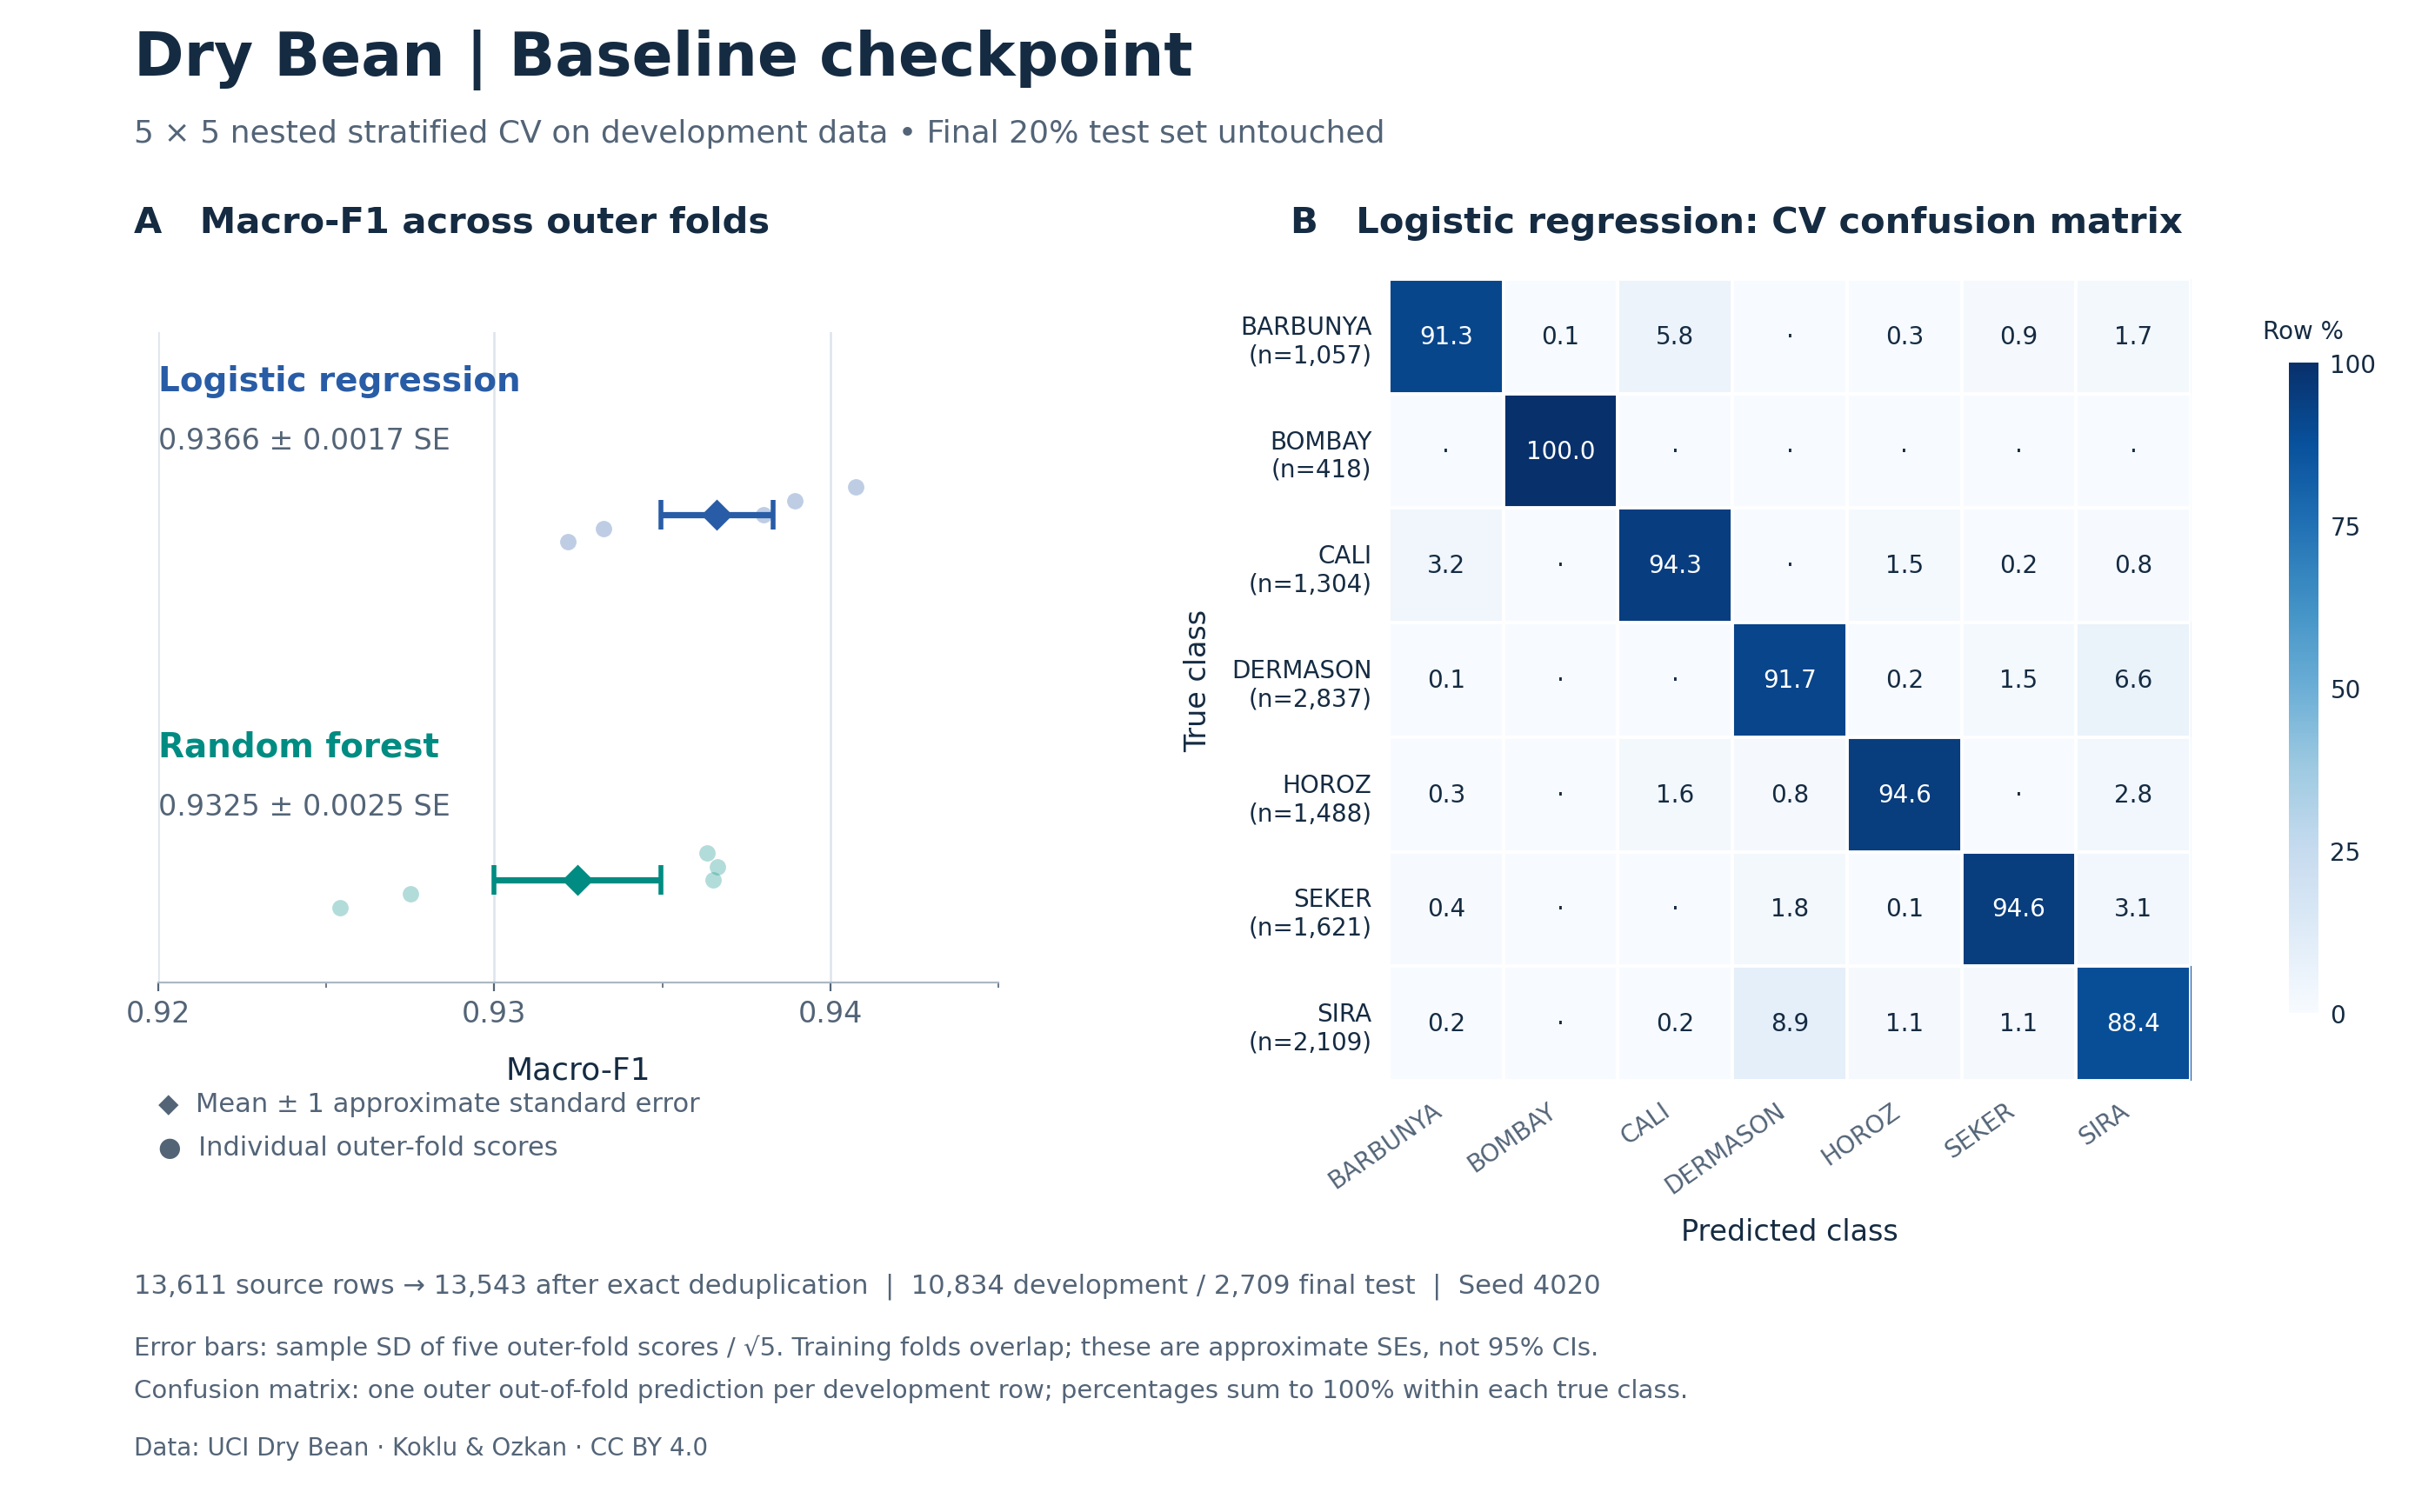

In [5]:
figure_path = draw()
display(Image(filename=str(figure_path)))

## Saved evidence and next steps

- `results/metrics.json`: scores, chosen parameters, source hash, and versions.
- `results/oof_predictions.csv`: source row IDs, outer folds, true labels, and both models' OOF predictions.
- `results/split_manifest.csv`: fixed development/final-test assignment.
- `results/inner_folds.csv`: inner validation assignments within each outer training partition.
- `results/*search.csv`: candidate settings and tuning-fold scores.
- `results/*cv_confusion_matrix.csv`: raw confusion counts.
- `results/dropped_duplicate_rows.csv`: source row IDs removed as exact duplicates.
- `baseline.png`: optional checkpoint submission figure.

Before **Monday 16 November**, Zihan documents preprocessing and maintains the baseline; Haodong completes single-tree and gradient-boosting searches using the same folds and 20-candidate budgets; Haoqian checks prediction alignment, prepares the final paired-bootstrap comparison, and drafts figures. The final test set remains untouched during this development.

Submit `baseline.txt` and optionally `baseline.png`; the assignment accepts `.txt` and `.png` only. The `## Code` section links to [this notebook on GitHub](https://github.com/AoLiGei1221/hello/blob/main/a.ipynb).